# PulmoSight 07 — Lung Segmentation & Lung-Focused Cropping

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


In [2]:
import torchxrayvision as xrv
from PIL import Image
from scipy import ndimage

splits = pd.read_csv(ROOT / "splits" / "splits.csv")
print(f"{len(splits):,} images in splits.csv")

seg = xrv.baseline_models.chestx_det.PSPNet().to(DEVICE).eval()
LEFT, RIGHT = seg.targets.index("Left Lung"), seg.targets.index("Right Lung")
print("Structures:", seg.targets)
print(f"Parameters: {sum(p.numel() for p in seg.parameters()) / 1e6:.1f}M")

def read_u8(path):
    return tvio.decode_image(tvio.read_file(str(ROOT / path)), mode=tvio.ImageReadMode.GRAY)

@torch.no_grad()
def segment(x_u8):
    """uint8 [B,1,512,512] -> sigmoid probabilities [B,14,512,512] (fp16 autocast)."""
    x = x_u8.to(DEVICE).float() / 255 * 2048 - 1024          # TorchXRayVision expects [-1024, 1024]
    with torch.autocast("cuda", dtype=torch.float16):
        return torch.sigmoid(seg(x).float())

16,785 images in splits.csv


Structures: ['Left Clavicle', 'Right Clavicle', 'Left Scapula', 'Right Scapula', 'Left Lung', 'Right Lung', 'Left Hilus Pulmonis', 'Right Hilus Pulmonis', 'Heart', 'Aorta', 'Facies Diaphragmatica', 'Mediastinum', 'Weasand', 'Spine']
Parameters: 68.1M


## 1. Image polarity — most of this dataset is stored inverted

Ambiguous images resolved by segmentation: 217


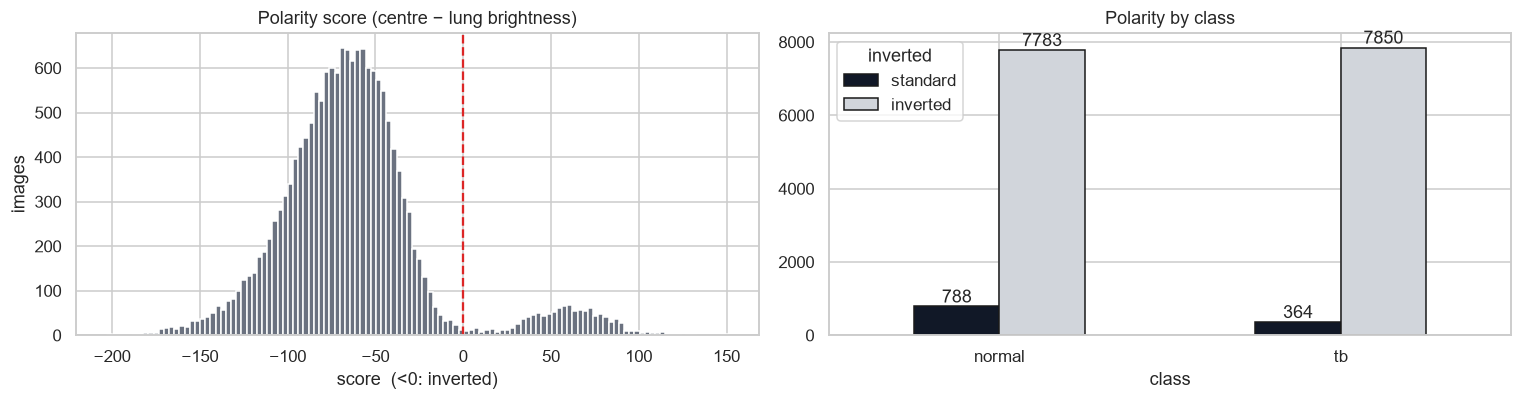

inverted      standard  inverted    All
split class                            
test  normal        78       783    861
      tb            45       775    820
train normal       629      6231   6860
      tb           290      6295   6585
val   normal        81       769    850
      tb            29       780    809
All               1152     15633  16785

P(Normal | standard polarity) = 0.68  vs  P(Normal) overall = 0.51  -> polarity alone carries label information: a shortcut we remove by standardising.


In [3]:
def polarity_score(path):
    x = read_u8(path)[0].float(); rows = slice(int(S * .30), int(S * .70))
    centre = x[rows, int(S * .45):int(S * .55)].mean()
    lungs = (x[rows, int(S * .18):int(S * .33)].mean() + x[rows, int(S * .67):int(S * .82)].mean()) / 2
    return float(centre - lungs)

S = IMAGE_SIZE
with ThreadPoolExecutor(16) as pool:
    splits["polarity_score"] = list(pool.map(polarity_score, splits.path))
splits["inverted"] = splits.polarity_score < 0

# Resolve ambiguous images with the segmenter: which version yields two plausible lungs?
amb = splits.index[splits.polarity_score.abs() < 15]
def lung_quality(probs):          # area of the smaller lung after thresholding
    return np.minimum((probs[:, LEFT] > 0.5).float().mean((1, 2)).cpu().numpy(), (probs[:, RIGHT] > 0.5).float().mean((1, 2)).cpu().numpy())
for i in range(0, len(amb), 8):
    idx = amb[i:i + 8]
    x = torch.stack([read_u8(p) for p in splits.path[idx]])
    q_as_is, q_flipped = lung_quality(segment(x)), lung_quality(segment(255 - x))
    splits.loc[idx, "inverted"] = q_flipped > q_as_is
print(f"Ambiguous images resolved by segmentation: {len(amb)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(splits.polarity_score, bins=120, color="#6B7280"); axes[0].axvline(0, color="#DC2626", ls="--")
axes[0].set(title="Polarity score (centre − lung brightness)", xlabel="score  (<0: inverted)", ylabel="images")
tab = pd.crosstab(splits["class"], splits.inverted).rename(columns={False: "standard", True: "inverted"})
tab.plot.bar(ax=axes[1], rot=0, color=["#111827", "#D1D5DB"], edgecolor="k"); axes[1].set_title("Polarity by class")
for c in axes[1].containers: axes[1].bar_label(c, fmt="%d")
plt.tight_layout(); plt.show()
display(pd.crosstab([splits.split, splits["class"]], splits.inverted, margins=True).rename(columns={False: "standard", True: "inverted"}))
std = splits[~splits.inverted]
print(f"P(Normal | standard polarity) = {(std.label == 0).mean():.2f}  vs  P(Normal) overall = {(splits.label == 0).mean():.2f}"
      "  -> polarity alone carries label information: a shortcut we remove by standardising.")

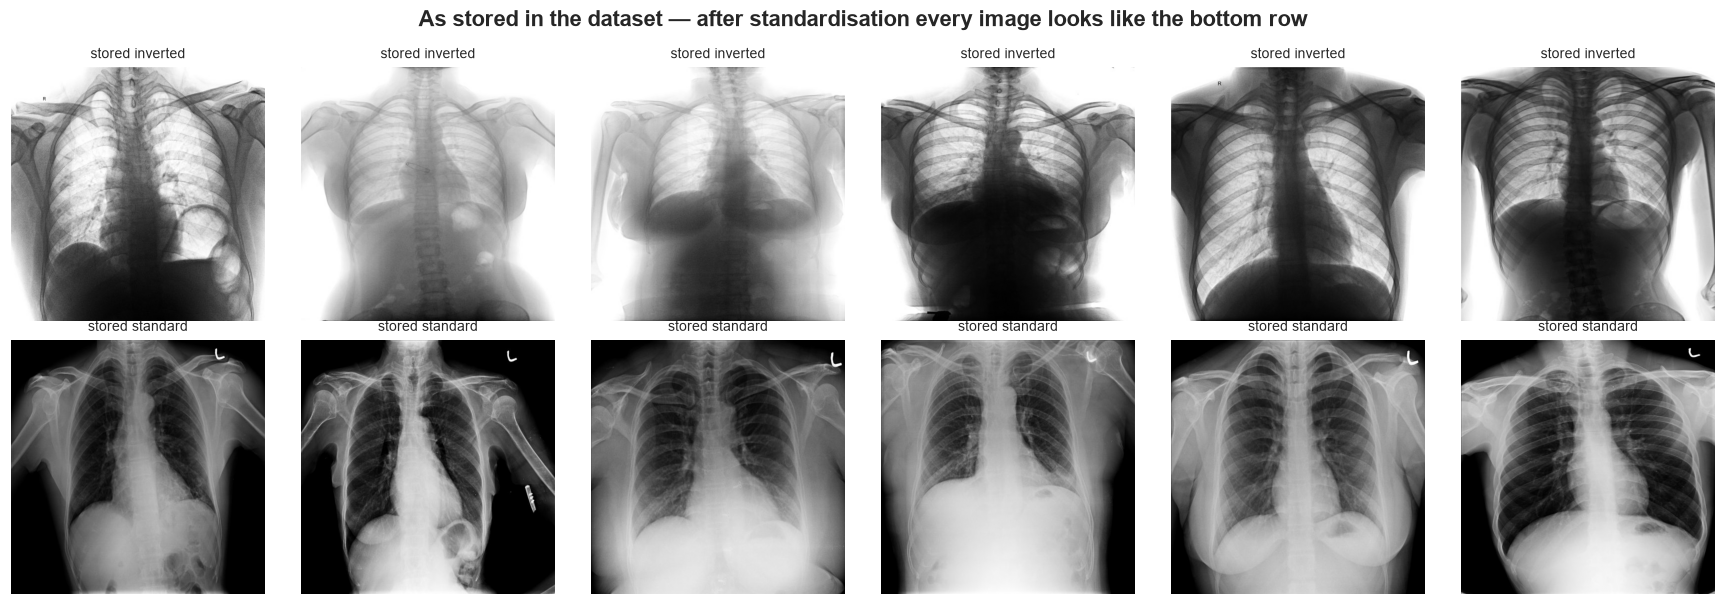

In [4]:
INVERT = set(splits.path[splits.inverted])
def read_std(path):
    """Read a cached X-ray and return it in STANDARD polarity (air dark, bone bright)."""
    x = read_u8(path)
    return 255 - x if path in INVERT else x

fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for r, inv in enumerate([True, False]):
    for ax, p in zip(axes[r], splits[splits.inverted == inv].sample(6, random_state=2).path):
        ax.imshow(read_u8(p)[0], cmap="gray"); ax.set_title(("stored inverted" if inv else "stored standard"), fontsize=9); ax.axis("off")
plt.suptitle("As stored in the dataset — after standardisation every image looks like the bottom row", weight="bold"); plt.tight_layout(); plt.show()

## 2. What the segmentation network sees

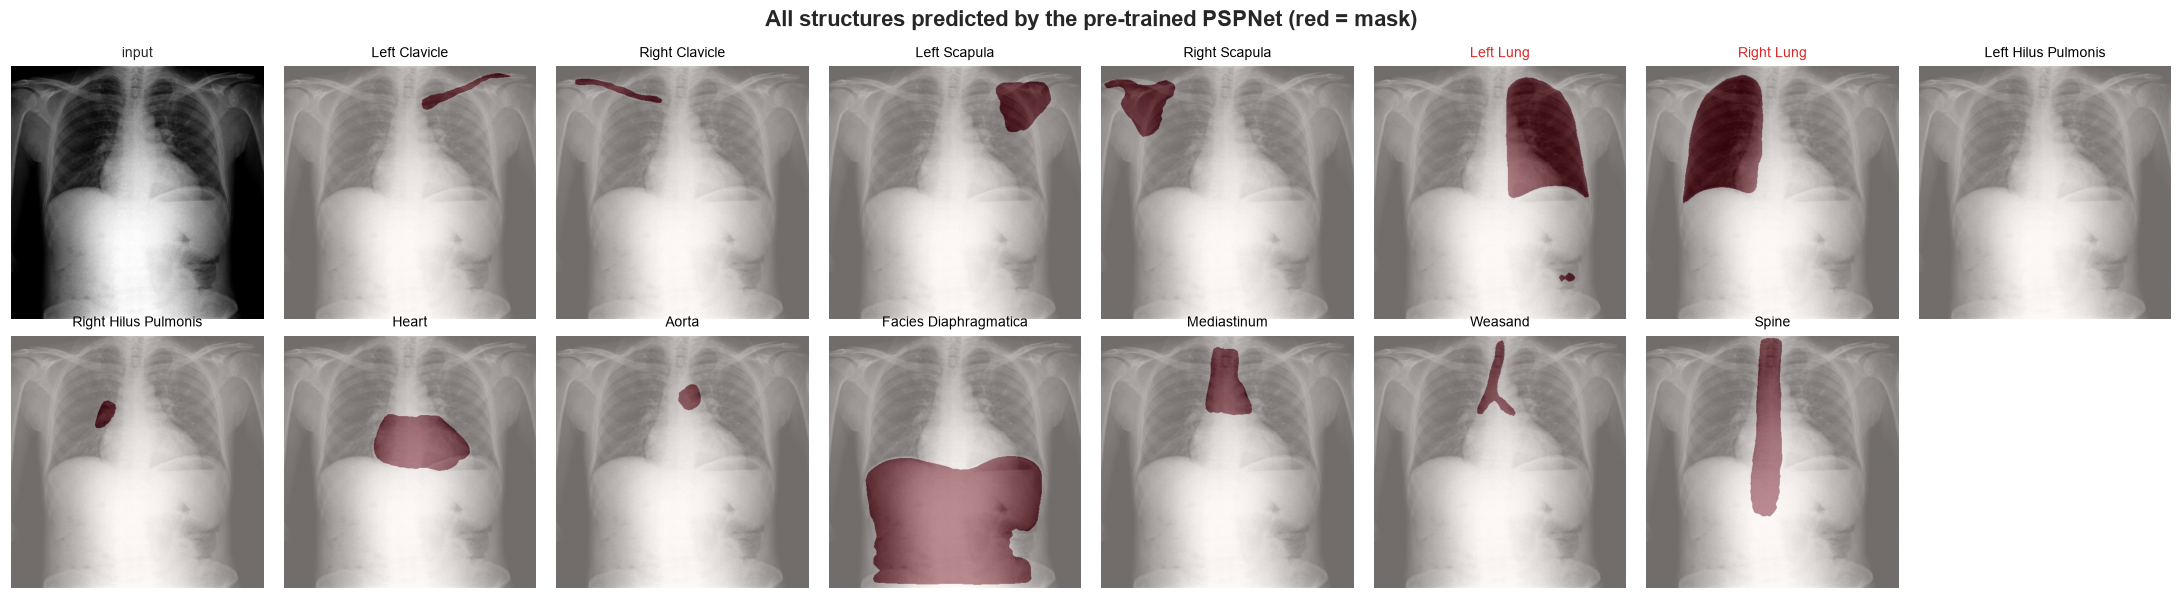

In [5]:
demo_path = splits[splits.label == 1].sample(1, random_state=7).path.iloc[0]
demo = read_std(demo_path)
probs = segment(demo[None])[0].cpu()
fig, axes = plt.subplots(2, 8, figsize=(20, 5.6))
axes[0, 0].imshow(demo[0], cmap="gray"); axes[0, 0].set_title("input", fontsize=9)
for ax, (name, p) in zip(axes.flat[1:], zip(seg.targets, probs)):
    ax.imshow(demo[0], cmap="gray"); ax.imshow(p > 0.5, cmap="Reds", alpha=0.45)
    ax.set_title(name, fontsize=9, color="#DC2626" if "Lung" in name else "black")
for ax in axes.flat: ax.axis("off")
plt.suptitle("All structures predicted by the pre-trained PSPNet (red = mask)", weight="bold"); plt.tight_layout(); plt.show()

## 3. Mask cleaning, cropping rule and quality control

In [6]:
MARGIN, MIN_LUNG, MAX_UNION, MIN_W, MIN_H = 0.06, 0.03, 0.65, 0.40, 0.35
FALLBACK = (0.06, 0.04, 0.94, 0.92)             # x0, y0, x1, y1 as fractions: centre crop that drops borders/labels
S = IMAGE_SIZE

def clean(mask):
    lab, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    return ndimage.binary_fill_holes(lab == (np.argmax(sizes) + 1))

def square_box(x0, y0, x1, y1):
    """Grow the shorter side so the box is square, then clip to the image."""
    w, h = x1 - x0, y1 - y0
    side = max(w, h)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    x0, x1 = cx - side / 2, cx + side / 2
    y0, y1 = cy - side / 2, cy + side / 2
    dx = max(0, -x0) - max(0, x1 - S); dy = max(0, -y0) - max(0, y1 - S)
    x0, x1, y0, y1 = x0 + dx, x1 + dx, y0 + dy, y1 + dy
    return [int(round(max(0, x0))), int(round(max(0, y0))), int(round(min(S, x1))), int(round(min(S, y1)))]

def process(path, img, left_p, right_p):
    """img: standard-polarity uint8 array [512,512]."""
    left, right = clean(left_p > 0.5), clean(right_p > 0.5)
    union = left | right
    lf, rf, uf = left.mean(), right.mean(), union.mean()
    reason = ""
    if lf < MIN_LUNG or rf < MIN_LUNG: reason = "lung missing / too small"
    elif uf > MAX_UNION: reason = "mask too large"
    if not reason:
        ys, xs = np.where(union)
        x0, x1, y0, y1 = xs.min() / S, (xs.max() + 1) / S, ys.min() / S, (ys.max() + 1) / S
        if x1 - x0 < MIN_W or y1 - y0 < MIN_H: reason = "box too small"
    if reason:
        x0, y0, x1, y1 = FALLBACK
    else:
        x0, y0 = max(0, x0 - MARGIN), max(0, y0 - MARGIN)
        x1, y1 = min(1, x1 + MARGIN), min(1, y1 + MARGIN)
    box = square_box(x0 * S, y0 * S, x1 * S, y1 * S)

    src = Image.fromarray(img)
    crop = src.crop(box).resize((S, S), Image.BICUBIC)
    mask_img = Image.fromarray(union.astype(np.uint8) * 255)
    crop_mask = mask_img.crop(box).resize((S, S), Image.NEAREST)
    out_img = ROOT / path.replace("cache512/", "lungcrop512/", 1)
    out_mask = ROOT / path.replace("cache512/", "lungmask512/", 1)
    out_cmask = ROOT / path.replace("cache512/", "lungcrop_mask512/", 1)
    for p, im in [(out_img, crop), (out_mask, mask_img), (out_cmask, crop_mask)]:
        p.parent.mkdir(parents=True, exist_ok=True); im.save(p)
    return {"path": path, "left_frac": lf, "right_frac": rf, "lung_frac": uf, "qc_fail": bool(reason), "qc_reason": reason,
            "box_x0": box[0], "box_y0": box[1], "box_x1": box[2], "box_y1": box[3],
            "crop_lung_frac": np.asarray(crop_mask).mean() / 255}

## 4. Segment and crop every X-ray (standard polarity)

In [7]:
BATCH = 8
paths = splits.path.tolist()
records = []
t0 = time.time()
with ThreadPoolExecutor(12) as io_pool, ThreadPoolExecutor(8) as cpu_pool:
    reads = deque(io_pool.submit(lambda b: torch.stack([read_std(p) for p in b]), paths[i:i + BATCH])
                  for i in range(0, min(len(paths), BATCH * 4), BATCH))
    next_start, pending = BATCH * 4, []
    for i in range(0, len(paths), BATCH):
        x = reads.popleft().result()
        if next_start < len(paths):
            reads.append(io_pool.submit(lambda b: torch.stack([read_std(p) for p in b]), paths[next_start:next_start + BATCH]))
            next_start += BATCH
        p = segment(x)[:, [LEFT, RIGHT]].cpu().numpy()
        imgs = x[:, 0].numpy()
        pending += [cpu_pool.submit(process, path, im, pl, pr) for path, im, (pl, pr) in zip(paths[i:i + BATCH], imgs, p)]
        if (i // BATCH) % 250 == 0:
            print(f"{i + len(x):>6,} / {len(paths):,}  ({(i + len(x)) / (time.time() - t0):.1f} img/s)")
    records = [f.result() for f in pending]
qc = pd.DataFrame(records).merge(splits[["path", "label", "class", "split"]], on="path")
print(f"\nDone: {len(qc):,} images in {(time.time() - t0) / 60:.1f} min")

     8 / 16,785  (15.4 img/s)


 2,008 / 16,785  (24.0 img/s)


 4,008 / 16,785  (24.1 img/s)


 6,008 / 16,785  (24.2 img/s)


 8,008 / 16,785  (24.0 img/s)


10,008 / 16,785  (24.4 img/s)


12,008 / 16,785  (24.5 img/s)


14,008 / 16,785  (24.6 img/s)


16,008 / 16,785  (24.8 img/s)



Done: 16,785 images in 11.3 min


## 5. Quality control

In [8]:
rate = qc.groupby(["split", "class"]).qc_fail.agg(["sum", "mean"]).rename(columns={"sum": "failed", "mean": "fail rate"})
display(rate.style.format({"fail rate": "{:.2%}"}))
print(qc[qc.qc_fail].qc_reason.value_counts().to_string())
from scipy.stats import chi2_contingency
ct = pd.crosstab(qc["class"], qc.qc_fail)
if ct.shape[1] == 2: print(f"\nChi-square test, failure rate TB vs Normal: p = {chi2_contingency(ct)[1]:.3g}")

qc_reason
lung missing / too small    15
box too small               11
mask too large               2

Chi-square test, failure rate TB vs Normal: p = 0.151


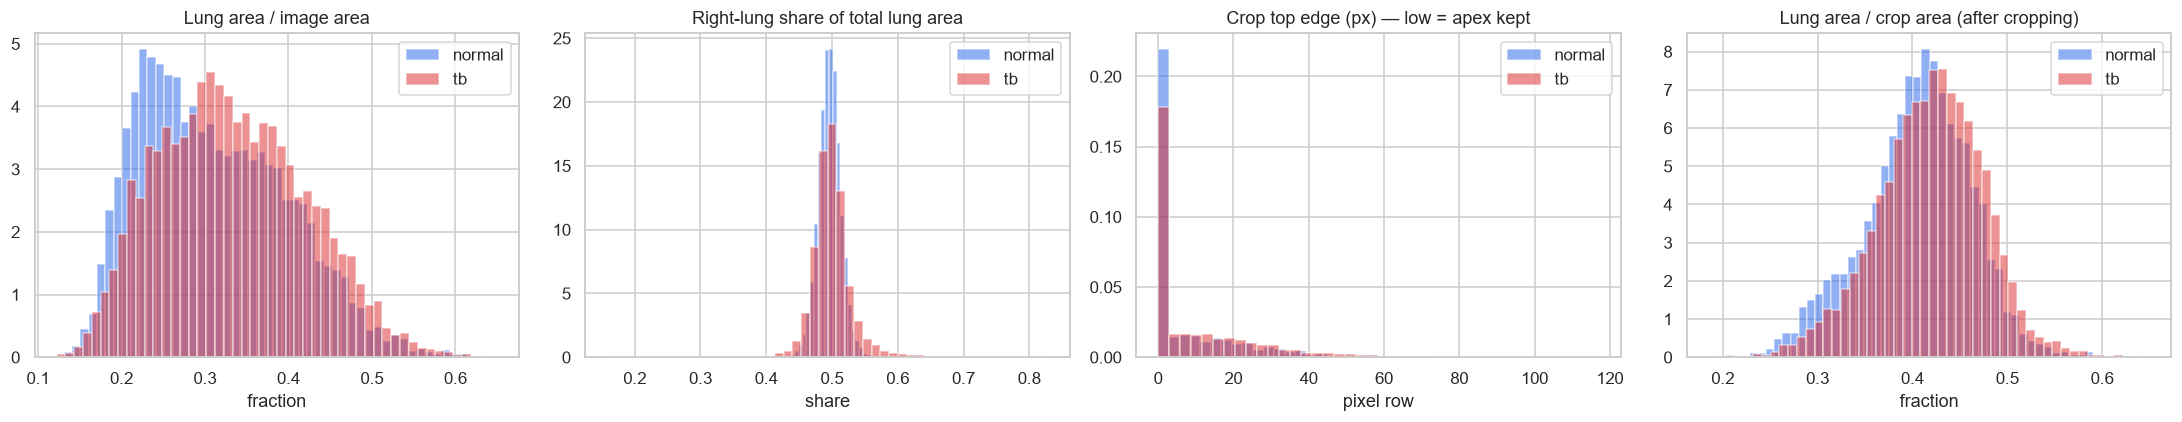

        lung_frac  crop_lung_frac  box_y0
class                                    
normal      0.299           0.409     0.0
tb          0.327           0.422     1.0


In [9]:
ok = qc[~qc.qc_fail]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for cls, color in zip(CLASSES, ["#2563EB", "#DC2626"]):
    d = ok[ok["class"] == cls]
    axes[0].hist(d.lung_frac, bins=50, alpha=0.5, color=color, density=True, label=cls)
    axes[1].hist(d.right_frac / (d.left_frac + d.right_frac), bins=50, alpha=0.5, color=color, density=True, label=cls)
    axes[2].hist(d.box_y0, bins=40, alpha=0.5, color=color, density=True, label=cls)
    axes[3].hist(d.crop_lung_frac, bins=50, alpha=0.5, color=color, density=True, label=cls)
axes[0].set(title="Lung area / image area", xlabel="fraction")
axes[1].set(title="Right-lung share of total lung area", xlabel="share")
axes[2].set(title="Crop top edge (px) — low = apex kept", xlabel="pixel row")
axes[3].set(title="Lung area / crop area (after cropping)", xlabel="fraction")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
print(ok.groupby("class")[["lung_frac", "crop_lung_frac", "box_y0"]].median().round(3))

### Visual check — random X-rays (top: mask + crop box, bottom: the crop the classifier will see)

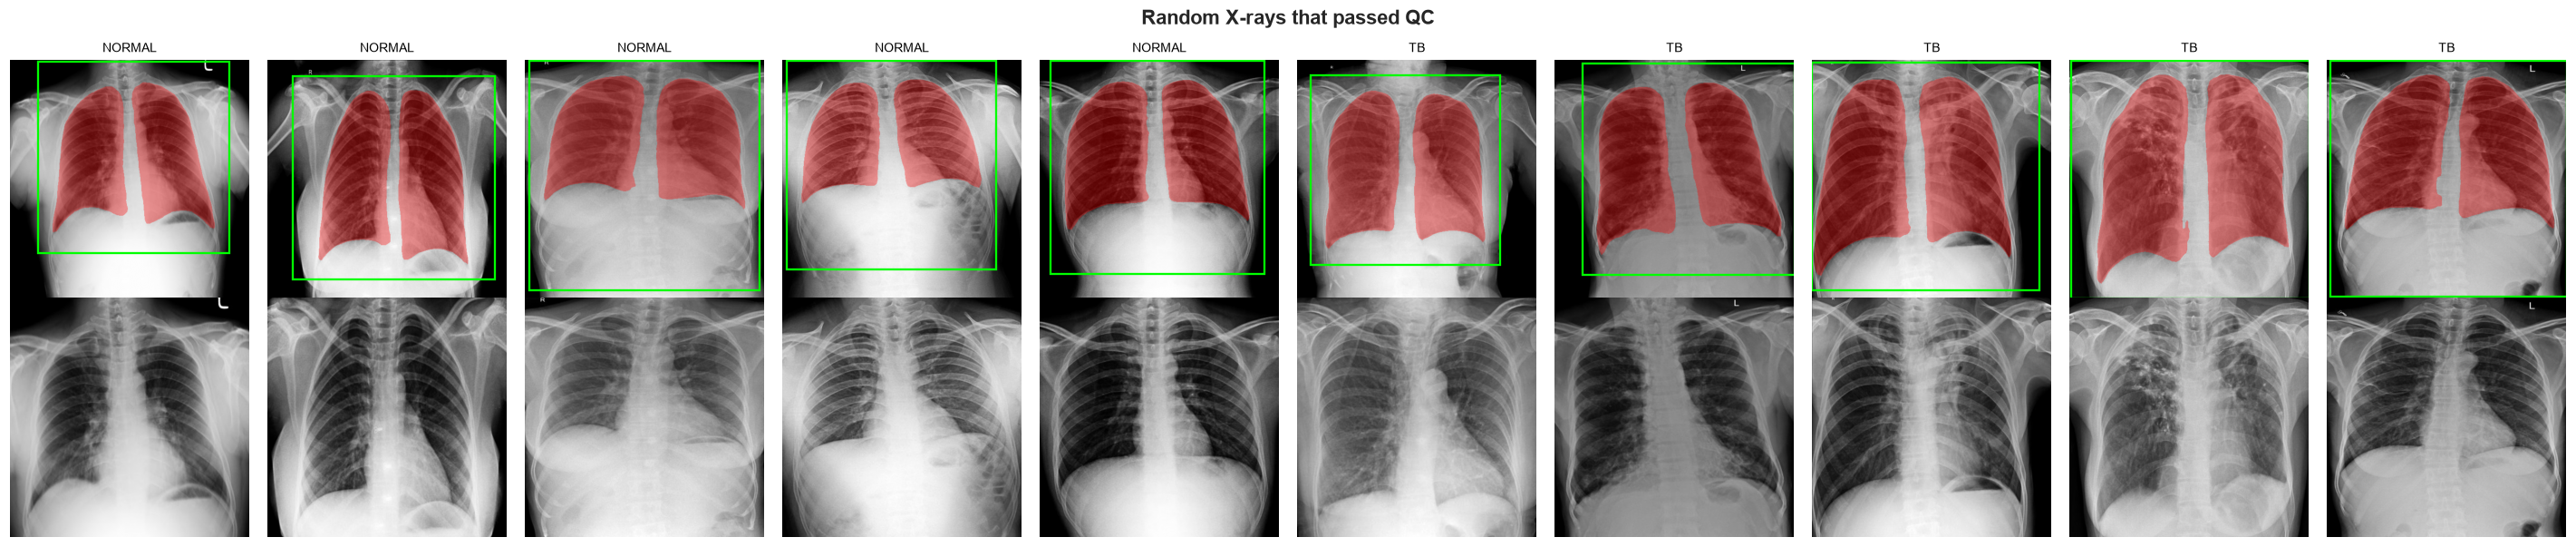

In [10]:
import matplotlib.patches as patches
def show_grid(rows, title):
    fig, axes = plt.subplots(2, len(rows), figsize=(2.6 * len(rows), 5.6))
    for j, (_, r) in enumerate(rows.iterrows()):
        img = read_std(r.path)[0]
        mask = np.asarray(Image.open(ROOT / r.path.replace("cache512/", "lungmask512/", 1)))
        crop = np.asarray(Image.open(ROOT / r.path.replace("cache512/", "lungcrop512/", 1)))
        axes[0, j].imshow(img, cmap="gray"); axes[0, j].imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.35)
        axes[0, j].add_patch(patches.Rectangle((r.box_x0, r.box_y0), r.box_x1 - r.box_x0, r.box_y1 - r.box_y0, fill=False, ec="lime", lw=1.5))
        axes[0, j].set_title(f"{r['class'].upper()}{' · QC FAIL' if r.qc_fail else ''}", fontsize=9, color="#DC2626" if r.qc_fail else "black")
        axes[1, j].imshow(crop, cmap="gray")
    for ax in axes.flat: ax.axis("off")
    fig.suptitle(title, weight="bold"); plt.tight_layout(); plt.show()

show_grid(qc[~qc.qc_fail].groupby("class").sample(5, random_state=1), "Random X-rays that passed QC")

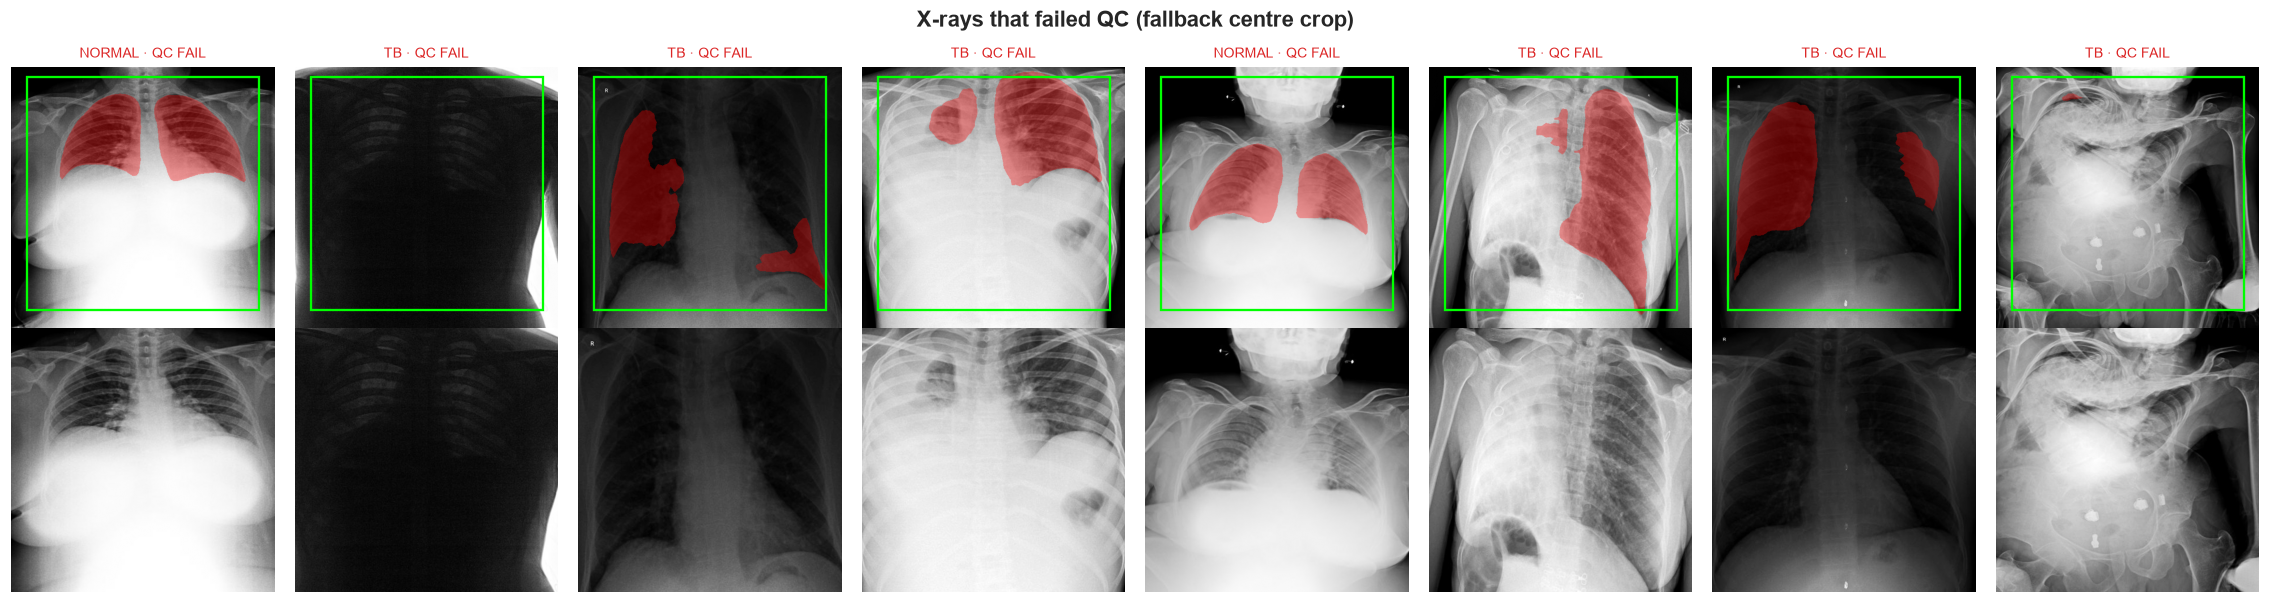

In [11]:
fails = qc[qc.qc_fail]
if len(fails):
    show_grid(fails.sample(min(8, len(fails)), random_state=0), "X-rays that failed QC (fallback centre crop)")
else:
    print("No QC failures.")

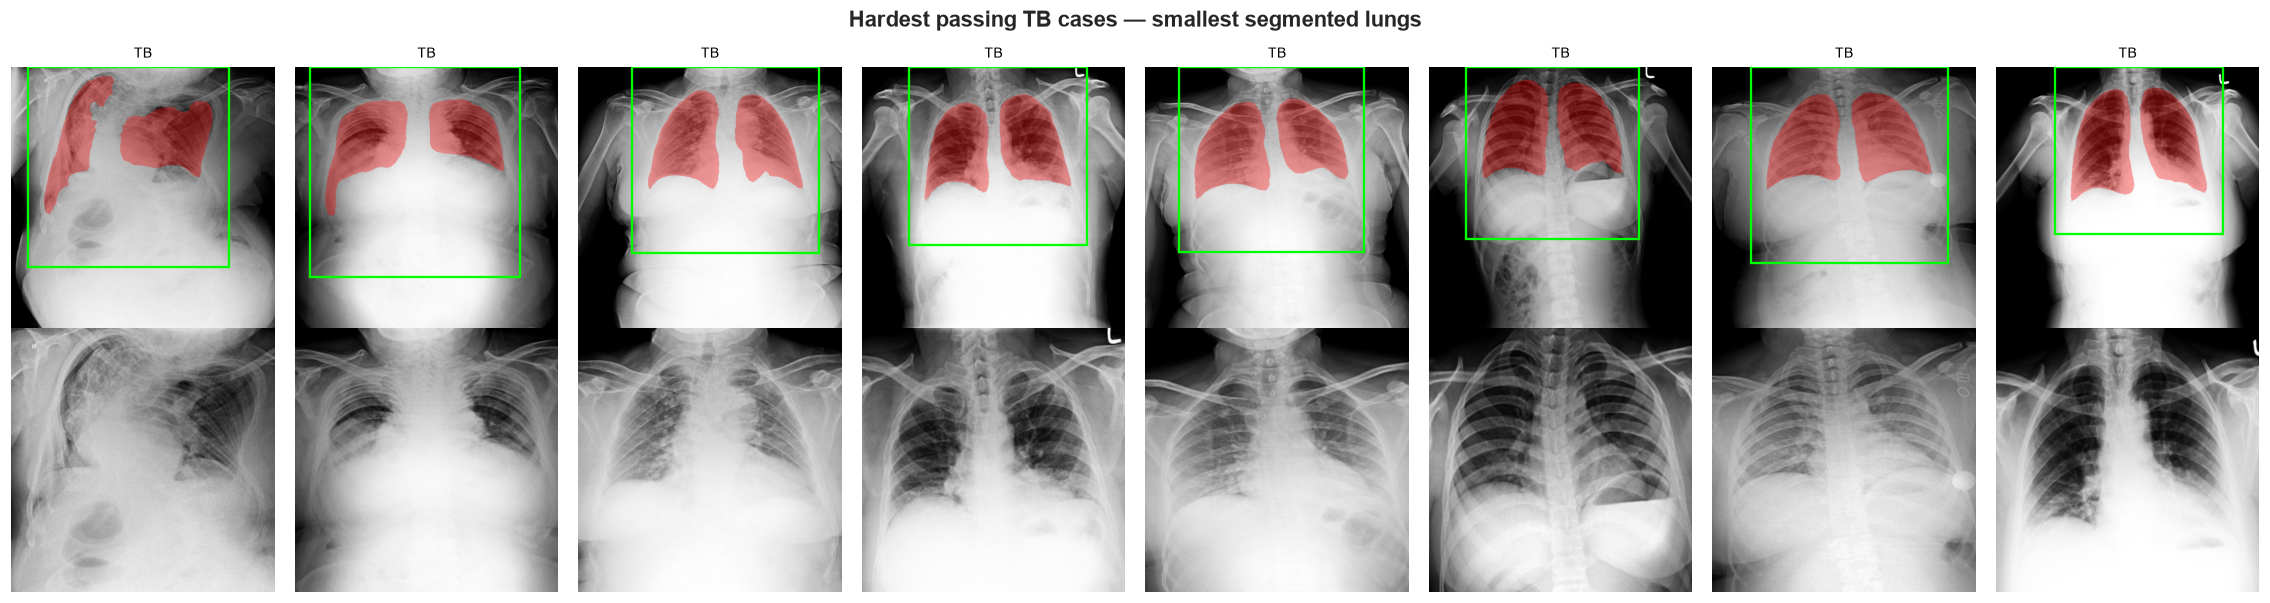

In [12]:
# The hardest cases: TB X-rays with the smallest segmented lungs that still passed QC
show_grid(ok[ok["class"] == "tb"].nsmallest(8, "lung_frac"), "Hardest passing TB cases — smallest segmented lungs")

## 6. Save the new split file

In [13]:
out = splits.copy()
out["path"] = out.path.str.replace("cache512/", "lungcrop512/", n=1, regex=False)
out["mask_path"] = splits.path.str.replace("cache512/", "lungmask512/", n=1, regex=False)
out["crop_mask_path"] = splits.path.str.replace("cache512/", "lungcrop_mask512/", n=1, regex=False)
out["orig_path"] = splits.path
out = out.merge(qc.drop(columns=["label", "class", "split"]).rename(columns={"path": "orig_path"}), on="orig_path")
out = out.drop(columns=["polarity_score", "inverted"], errors="ignore").merge(
    splits[["path", "polarity_score", "inverted"]].rename(columns={"path": "orig_path", "inverted": "stored_inverted"}), on="orig_path")
out.to_csv(ROOT / "splits" / "splits_lungcrop.csv", index=False)
print(f"Saved {len(out):,} rows -> splits/splits_lungcrop.csv")
print(f"QC failures: {out.qc_fail.sum()} ({out.qc_fail.mean():.2%}) — kept with a centre-crop fallback and flagged")
out.head(3)

Saved 16,785 rows -> splits/splits_lungcrop.csv
QC failures: 28 (0.17%) — kept with a centre-crop fallback and flagged


,path,label,class,split,near_dup_of_train,mask_path,crop_mask_path,orig_path,left_frac,right_frac,lung_frac,qc_fail,qc_reason,box_x0,box_y0,box_x1,box_y1,crop_lung_frac,polarity_score,stored_inverted
0,lungcrop512/train/normal/0005931495bf3d305a045...,0,normal,train,False,lungmask512/train/normal/0005931495bf3d305a045...,lungcrop_mask512/train/normal/0005931495bf3d30...,cache512/train/normal/0005931495bf3d305a04572d...,0.097145,0.090164,0.187309,False,,103,47,440,384,0.432091,22.723679,False
1,lungcrop512/train/normal/003238542a63c2b240c05...,0,normal,train,False,lungmask512/train/normal/003238542a63c2b240c05...,lungcrop_mask512/train/normal/003238542a63c2b2...,cache512/train/normal/003238542a63c2b240c05c51...,0.190132,0.173023,0.363155,False,,34,35,481,482,0.476528,-74.367920,True
2,lungcrop512/train/normal/003ce096c6aa290f6beb2...,0,normal,train,False,lungmask512/train/normal/003ce096c6aa290f6beb2...,lungcrop_mask512/train/normal/003ce096c6aa290f...,cache512/train/normal/003ce096c6aa290f6beb2930...,0.182400,0.193073,0.375473,False,,26,15,509,498,0.422108,-66.900513,True
